# Bivariate data - the basics

This tutorial focuses on working with paired (bivariate) data using `plans`: loading `x`/`y` samples, inspecting their joint distribution, fitting simple regression models and assessing the model errors.

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/bivariate")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\bivariate


## The `Bivar` object

The `Bivar` object lives under the `plans.analyst` module. Like `Univar`, it is a child of the `DataSet` object from `plans.root`, so it shares the same lifecycle: create the object, feed it data, and let `.update()` refresh the derived attributes.

```{seealso}
Check out the {doc}`Univariate data - the basics <univar_01>` tutorial first.
```

Import `Bivar` object:

In [2]:
from plans.analyst import Bivar

Create an instance of the `Bivar`:

In [3]:
bv = Bivar(name="Rating Curve", alias="RC")

Check out the variable type:

In [4]:
print(type(bv))

<class 'plans.analyst.Bivar'>


## Handle data attributes

Columns are named by `.xfield` and `.yfield`, while `.xname`, `.yname`, `.xunits` and `.yunits` are only used as labels in visuals and metadata. Set labels **before** loading data, so the axis labels are built from them:

In [5]:
bv.description = "Stage-discharge pairs for a tutorial"
bv.xname = "Stage"
bv.xunits = "m"
bv.yname = "Discharge"
bv.yunits = "m3/s"
print(f"x column: {bv.xfield} | y column: {bv.yfield}")

x column: x | y column: y


## Working with data

### Create synthetic power-law dataset

Stage-discharge relations (rating curves) are a classic bivariate case in hydrology. Lets make a synthetic one following a power law plus gaussian noise, shuffle the rows and add a couple of missing values, then save it to a CSV file.

In [6]:
# make synthetic power-law data
rng = np.random.default_rng(seed=42)  # ensure reproducibility
h = np.linspace(start=0.5, stop=3.0, num=200)
q = 5 * np.power(h, 1.6) + rng.normal(loc=0, scale=1, size=len(h))
df = pd.DataFrame({"stage": h, "discharge": q})

# shuffle rows and add missing values
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.loc[[3, 7], "discharge"] = np.nan

# Export CSV file
file_csv = OUTPUT_DIR / "bivariate_rating.csv"
df.to_csv(file_csv, sep=";", index=False)
print(f"Saved to: {file_csv}")
df.head()

Saved to: outputs\bivariate\bivariate_rating.csv


,stage,discharge
0,1.693467,10.167719
1,0.688442,1.892135
2,0.876884,6.193725
3,2.484925,NaN
4,2.108040,15.848562


### Loading data from the CSV file

Call the `.load_data()` method, pointing which file columns hold `x` and `y`. They are renamed to `.xfield` and `.yfield` on loading:

In [7]:
bv.load_data(
    file_data=file_csv,  # file path
    input_xfield="stage",  # name of x column
    input_yfield="discharge",  # name of y column
    in_sep=";",  # input separator
)

Data is stored in the `.data` attribute as a `pandas.DataFrame`. Incomplete pairs are dropped and rows are sorted by `x`:

In [8]:
bv.data

,x,y
0,0.500000,1.954102
1,0.512563,0.676206
2,0.525126,2.534436
3,0.537688,2.793325
4,0.550251,-0.028529
...,...,...
193,2.949749,27.329759
194,2.962312,29.060389
195,2.974874,28.215524
196,2.987437,28.798563


```{tip}
For in-memory arrays, use `.set_data(x=..., y=...)` instead. It applies the same cleaning and sorting.
```

### Access computed attributes

After loading data, some attributes are computed automatically:

In [9]:
print(f"Size: {bv.size}")
print(f"x range: {bv.x_min:.2f} to {bv.x_max:.2f}")
print(f"y range: {bv.y_min:.2f} to {bv.y_max:.2f}")
print(f"Pearson R: {bv.corr:.3f}")

Size: 198
x range: 0.50 to 3.00
y range: -0.03 to 29.30
Pearson R: 0.986


Inspect the object metadata:

In [10]:
bv.get_metadata()

{'name': 'Rating Curve',
 'alias': 'RC',
 'size': 198,
 'color': 'blue',
 'source': None,
 'description': 'Stage-discharge pairs for a tutorial',
 'xunits': 'm',
 'yunits': 'm3/s',
 'file_data': 'C:\\Users\\Ipo\\AppData\\Local\\Temp\\claude\\C--Users-Ipo-PycharmProjects-plans\\f8d04d3e-cf5c-442f-b56e-ee185207a61b\\scratchpad\\nbrun\\outputs\\bivariate\\bivariate_rating.csv'}

## Visualizations

### Standard visualization

Get the standard visual using the `.view()` method. The `full` layout shows the scatter plot with the marginal histograms of `x` (top) and `y` (right):

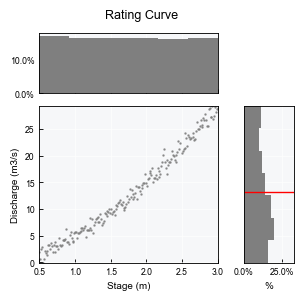

In [11]:
bv.view()

### Fine-tuning visuals

Like other `plans` objects, use the `.view_specs` keys for fine tuning:

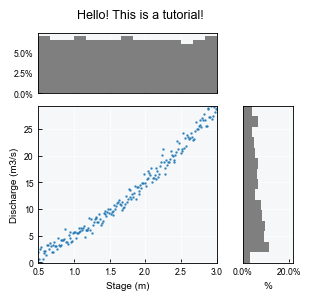

In [12]:
bv.view_specs["color"] = "tab:blue"
bv.view_specs["bins"] = 15  # default None uses the Freedman-Diaconis rule
bv.view_specs["plot_mean"] = False
bv.view_specs["title"] = "Hello! This is a tutorial!"
bv.view()

## Fitting models

### Available models

Models are stored in the `.models` dictionary. Each entry holds the function, its formula, a `Setup` table of parameters and, once computed, the model `Data` and the `RMSE`:

In [13]:
for model_type, model in bv.models.items():
    print(f"{model_type:<12} {model['Formula']}")

Linear       f(x) = c0 + c1 * x
Power        f(x) =  c2 * ((x + c0)^c1)
Power_zero   f(x) =  c1 * (x^c0)


### Fit a model

The `.fit()` method runs a least squares fit and stores the mean and standard deviation of parameters in the `Setup` table:

In [14]:
bv.fit(model_type="Power")
bv.models["Power"]["Setup"]

,Parameters,Mean,SD
0,c0,0.094287,0.091403
1,c1,1.700409,0.082639
2,c2,4.279183,0.593650


The model `Data` holds the predictions (`y_Mean`) and the errors (`e_Mean`, model minus observed):

In [15]:
bv.models["Power"]["Data"].head()

,x,y,y_Mean,e_Mean
0,0.500000,1.954102,1.766291,-0.187811
1,0.512563,0.676206,1.830250,1.154044
2,0.525126,2.534436,1.895143,-0.639293
3,0.537688,2.793325,1.960965,-0.832359
4,0.550251,-0.028529,2.027710,2.056239


### Compare models

Fit all models and compare their RMSE:

In [16]:
for model_type in bv.models:
    bv.fit(model_type=model_type)
    print(f"{model_type:<12} RMSE = {bv.models[model_type]['RMSE']:.3f}")

Linear       RMSE = 1.337
Power        RMSE = 0.878
Power_zero   RMSE = 0.881


### Set parameters manually

Parameters can also be set by hand with `.update_model()`, for instance to test a known reference curve:

In [17]:
bv.update_model(params_mean=[1.5, 5.0], model_type="Power_zero")
print(f"RMSE = {bv.models['Power_zero']['RMSE']:.3f}")

RMSE = 1.589


## Model assessment

### Model panel

Set the `model` layout and the `model_type` key to get the model panel. It shows the fitted curve, how the error variance evolves along `x`, the errors, their histogram and a Q-Q plot against the normal distribution:

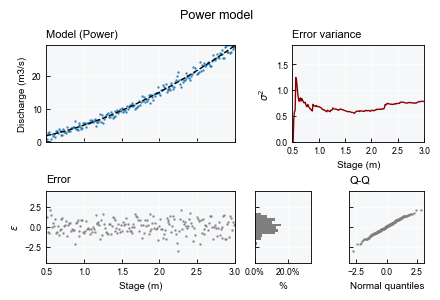

In [18]:
bv.fit(model_type="Power")
bv.view_specs["layout"] = "model"
bv.view_specs["model_type"] = "Power"
bv.view_specs["title"] = "Power model"
bv.view()

### Error normality

Assess if model errors are normal via the `.get_error_normality()` method:

In [19]:
df = bv.get_error_normality(model_type="Power", clevel=0.95)
df

,Test,Statistic,p-value,is_normal,Confidence
0,Kolmogorov-Smirnov,0.041331,0.873566,True,0.95
1,Shapiro-Wilk,0.992896,0.454820,True,0.95
2,D'Agostino-Pearson,2.084696,0.352626,True,0.95


### Goodness-of-fit metrics

Static methods are available for common metrics between predicted and observed values:

In [20]:
df_model = bv.models["Power"]["Data"]
pred = df_model[f"{bv.yfield}_Mean"].values
obs = df_model[bv.yfield].values

print(f"RMSE: {Bivar.rmse(pred=pred, obs=obs):.3f}")
print(f"MAE: {Bivar.mae(pred=pred, obs=obs):.3f}")
print(f"R2: {Bivar.rsq(pred=pred, obs=obs):.3f}")
print(f"Bias (%): {Bivar.bias(pred=pred, obs=obs):.3f}")

RMSE: 0.878
MAE: 0.709
R2: 0.988
Bias (%): 0.008
